In [2]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import yaml
import os

In [3]:
import torch
from deep_hedging.black_scholes import black_scholes_call_price

In [21]:
entropic_run_path = Path("../runs/entropic_nocost_seed0")
cvar_run_path = Path("../runs/cvar_nocost_seed0")

In [22]:
entropic_loss_path = os.path.join(entropic_run_path, "model_history.csv")
entropic_loss = pl.read_csv(entropic_loss_path)
print(entropic_loss)

cvar_loss_path = os.path.join(cvar_run_path, "model_history.csv")
cvar_loss = pl.read_csv(cvar_loss_path)
print(cvar_loss)

shape: (2_000, 1)
┌───────────┐
│ loss      │
│ ---       │
│ f64       │
╞═══════════╡
│ 14.313739 │
│ 13.99348  │
│ 17.475082 │
│ 12.807046 │
│ 11.973056 │
│ …         │
│ 2.4383    │
│ 2.469373  │
│ 2.456273  │
│ 2.452889  │
│ 2.464328  │
└───────────┘
shape: (2_000, 1)
┌──────────┐
│ loss     │
│ ---      │
│ f64      │
╞══════════╡
│ 5.050418 │
│ 5.02142  │
│ 5.455573 │
│ 5.191586 │
│ 5.129601 │
│ …        │
│ 2.659975 │
│ 2.663345 │
│ 2.677938 │
│ 2.655772 │
│ 2.688707 │
└──────────┘


In [23]:
entropic_loss = entropic_loss.with_columns(pl.col("loss").rolling_mean(window_size=100, min_samples=1).alias("loss_rolling_mean"))
entropic_loss = entropic_loss.with_row_index("iter")
print(entropic_loss.head())

cvar_loss = cvar_loss.with_columns(pl.col("loss").rolling_mean(window_size=100, min_samples=1).alias("loss_rolling_mean"))
cvar_loss = cvar_loss.with_row_index("iter")
print(cvar_loss.head())

shape: (5, 3)
┌──────┬───────────┬───────────────────┐
│ iter ┆ loss      ┆ loss_rolling_mean │
│ ---  ┆ ---       ┆ ---               │
│ u32  ┆ f64       ┆ f64               │
╞══════╪═══════════╪═══════════════════╡
│ 0    ┆ 14.313739 ┆ 14.313739         │
│ 1    ┆ 13.99348  ┆ 14.153609         │
│ 2    ┆ 17.475082 ┆ 15.260767         │
│ 3    ┆ 12.807046 ┆ 14.647337         │
│ 4    ┆ 11.973056 ┆ 14.112481         │
└──────┴───────────┴───────────────────┘
shape: (5, 3)
┌──────┬──────────┬───────────────────┐
│ iter ┆ loss     ┆ loss_rolling_mean │
│ ---  ┆ ---      ┆ ---               │
│ u32  ┆ f64      ┆ f64               │
╞══════╪══════════╪═══════════════════╡
│ 0    ┆ 5.050418 ┆ 5.050418          │
│ 1    ┆ 5.02142  ┆ 5.035919          │
│ 2    ┆ 5.455573 ┆ 5.175804          │
│ 3    ┆ 5.191586 ┆ 5.179749          │
│ 4    ┆ 5.129601 ┆ 5.16972           │
└──────┴──────────┴───────────────────┘


In [27]:
config_path = os.path.join(entropic_run_path, "config.yaml")

In [28]:
with open(cvar_config_path) as f:
    config = yaml.safe_load(f)

S0 = config["market"]["S0"]
mu = config["market"]["mu"]
sigma = config["market"]["sigma"]
T = config["market"]["T"]
n_steps = config["market"]["n_steps"]
K = config["option"]["K"]

bs_price = black_scholes_call_price(S=torch.tensor(S0, dtype=torch.float32), K=K, tau=torch.tensor(T, dtype=torch.float32), sigma=sigma).item()
print(bs_price)

2.2871475219726562


d:\Perso_Projects\Perso_Projects\DeepHedging\.venv\Lib\site-packages\seaborn\_core\data.py:313: UserWarning: Conversion using Arrow PyCapsule Interface failed due to missing PyArrow>=14 dependency, falling back to (deprecated) interchange protocol. We recommend that you install PyArrow>=14.0.0.
  return pd.api.interchange.from_dataframe(data)
d:\Perso_Projects\Perso_Projects\DeepHedging\.venv\Lib\site-packages\seaborn\_core\data.py:313: UserWarning: Conversion using Arrow PyCapsule Interface failed due to missing PyArrow>=14 dependency, falling back to (deprecated) interchange protocol. We recommend that you install PyArrow>=14.0.0.
  return pd.api.interchange.from_dataframe(data)
d:\Perso_Projects\Perso_Projects\DeepHedging\.venv\Lib\site-packages\seaborn\_core\data.py:313: UserWarning: Conversion using Arrow PyCapsule Interface failed due to missing PyArrow>=14 dependency, falling back to (deprecated) interchange protocol. We recommend that you install PyArrow>=14.0.0.
  return pd.ap

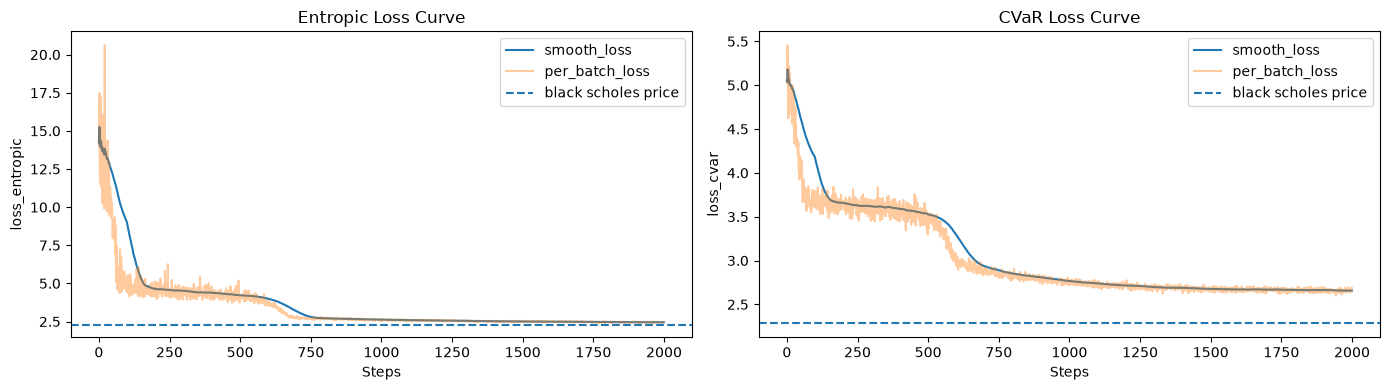

In [29]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

# Entropic Loss
sns.lineplot(data=entropic_loss, x="iter", y="loss_rolling_mean", ax=ax1, label="smooth_loss")
sns.lineplot(data=entropic_loss, x="iter", y="loss", ax=ax1, alpha=0.4, label="per_batch_loss")
ax1.axhline(bs_price, linestyle="--", label="black scholes price")
ax1.set_xlabel("Steps")
ax1.set_ylabel("loss_entropic")
ax1.set_title("Entropic Loss Curve")
ax1.legend()

# CVaR Loss
sns.lineplot(data=cvar_loss, x="iter", y="loss_rolling_mean", ax=ax2, label="smooth_loss")
sns.lineplot(data=cvar_loss, x="iter", y="loss", ax=ax2, alpha=0.4, label="per_batch_loss")
ax2.axhline(bs_price, linestyle="--", label="black scholes price")
ax2.set_xlabel("Steps")
ax2.set_ylabel("loss_cvar")
ax2.set_title("CVaR Loss Curve")
ax2.legend()

fig.tight_layout()
fig.savefig("results/loss_curve/training_loss.png", dpi=150, bbox_inches="tight")

The Entropic plot shows that the loss plumets before stabilizing around the step 200 showing a much gentler steep until step 600.

The CVaR training loss shows a much gentler slope between steps ~200 to 550 at a loss~3.6 before further decreasing.

-> the optimizer seems to get stuck

Needs further investigation: 

In [ ]:
from deep_hedging.delta import bs_hedge_policy
from deep_hedging.risk import entropic_risk, cvar_empirical
from deep_hedging.gbm import simulate_gbm
from deep_hedging.engine import pnl
from deep_hedging.payoffs import call_payoff

In [49]:
n_paths = config["test"]["n_paths"]
lam = config["risk"]["lam"]
alpha = config["risk"]["alpha"]    
torch.manual_seed(config["test_seed"])
_, test_S = simulate_gbm(S0, mu, sigma, T, n_steps, n_paths)

payoff_ = call_payoff(K, test_S[:,-1, 0])


entropic_loss = []
cvar_loss = []

min_entropic = 15
min_cvar = 15

cs =  torch.linspace(0.0, 1.0, 21)

for c in cs:
    delta_cst = torch.full_like(test_S[:, :-1, :], c)

    pnl_ = pnl(payoff=payoff_, S=test_S, delta=delta_cst, p0=0.0, c=0.0)
    
    temp_entropic = entropic_risk(pnl_, lam)
    
    temp_cvar = cvar_empirical(pnl_, alpha)[1]

    if temp_entropic.item() < min_entropic:
        c_star_entropic = c.item()
        min_entropic = temp_entropic.item()
    
    if temp_cvar.item() < min_cvar:
        c_star_cvar = c.item()
        min_cvar = temp_cvar.item()

    entropic_loss.append(temp_entropic)
    cvar_loss.append(cvar_empirical(pnl_, alpha)[1])

print(f"Min Entropic Loss with constant Hedge: {min_entropic:.2f} atteined in: {c_star_entropic:.2f}")
print(f"Min CVaR Loss with constant Hedge: {min_cvar:.2f} atteined in: {c_star_cvar:.2f} ")

Min Entropic Loss with constant Hedge: 4.65 atteined in: 0.55
Min CVaR Loss with constant Hedge: 3.64 atteined in: 0.50 
